In [9]:
from xgboost import XGBClassifier

In [10]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from xgboost import XGBClassifier

In [11]:
import pandas as pd

errors = pd.read_csv("../results/test_error_analysis.csv")

false_negatives = errors[errors["error_type"] == "False Negative"]
false_positives = errors[errors["error_type"] == "False Positive"]

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))

False Negatives: 1015
False Positives: 1465


In [2]:
import pandas as pd

TARGET_COL = "SeriousDlqin2yrs"

# Load original test dataset
test = pd.read_csv("../data/test.csv")

# Separate features and actual target
X_test_features = test.drop(columns=[TARGET_COL])

# Check row alignment before combining
assert len(X_test_features) == len(errors), "Row counts do not match!"

# Combine original features with saved predictions
error_analysis = pd.concat(
    [
        X_test_features.reset_index(drop=True),
        errors.reset_index(drop=True)
    ],
    axis=1
)

print("Combined dataset shape:", error_analysis.shape)
print("Error types:")
print(error_analysis["error_type"].value_counts())

Combined dataset shape: (30000, 14)
Error types:
error_type
Correct           27520
False Positive     1465
False Negative     1015
Name: count, dtype: int64


In [3]:
false_negatives = error_analysis[
    error_analysis["error_type"] == "False Negative"
]

false_positives = error_analysis[
    error_analysis["error_type"] == "False Positive"
]

# Select 20 examples from each group
fn_samples = false_negatives.head(20)
fp_samples = false_positives.head(20)

print("FALSE NEGATIVES — 20 EXAMPLES")
display(fn_samples)

print("FALSE POSITIVES — 20 EXAMPLES")
display(fp_samples)

FALSE NEGATIVES — 20 EXAMPLES


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,actual,probability,predicted,error_type
29,0.244881,63,2,0.406865,6350.0,14,0,3,0,0.0,1,0.097471,0,False Negative
50,0.669376,51,0,1.106946,13258.0,23,0,2,0,2.0,1,0.114276,0,False Negative
86,0.122707,32,0,0.390743,7820.0,16,0,2,0,1.0,1,0.034827,0,False Negative
115,0.001882,35,1,0.330763,5834.0,5,0,1,0,4.0,1,0.036885,0,False Negative
139,0.546625,40,1,0.098309,14250.0,4,1,0,0,0.0,1,0.181150,0,False Negative
179,0.211747,49,0,0.573242,6300.0,27,0,2,0,3.0,1,0.034592,0,False Negative
188,0.234510,23,0,0.143959,2333.0,2,0,0,0,0.0,1,0.022530,0,False Negative
204,1.052732,50,0,0.431105,15000.0,11,0,2,1,2.0,1,0.227342,0,False Negative
243,0.275776,62,0,0.181737,4500.0,13,0,0,0,0.0,1,0.021513,0,False Negative
453,1.000000,38,1,940.000000,NaN,1,0,1,0,0.0,1,0.208963,0,False Negative


FALSE POSITIVES — 20 EXAMPLES


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,actual,probability,predicted,error_type
31,1.000000,45,0,1008.000000,NaN,2,1,1,1,3.0,0,0.540412,1,False Positive
35,0.462444,45,2,1.520517,4800.0,12,0,3,0,0.0,0,0.293365,1,False Positive
45,0.883107,66,1,0.010964,3100.0,3,1,0,0,0.0,0,0.307785,1,False Positive
89,0.817265,48,4,1.464927,2950.0,19,0,1,3,3.0,0,0.609625,1,False Positive
99,0.889853,30,0,0.071186,5000.0,3,1,0,0,0.0,0,0.261183,1,False Positive
119,0.769231,48,2,0.292694,6692.0,6,1,2,1,2.0,0,0.431272,1,False Positive
129,0.457319,68,4,0.560710,8276.0,18,1,1,0,0.0,0,0.394699,1,False Positive
149,0.000000,37,3,0.151378,6420.0,3,1,0,3,3.0,0,0.624099,1,False Positive
203,0.893311,51,3,5734.000000,NaN,15,0,3,1,0.0,0,0.460941,1,False Positive
227,1.400830,39,0,0.690164,4340.0,16,0,1,0,1.0,0,0.317470,1,False Positive


In [4]:
# Compare average feature values
comparison = pd.DataFrame({
    "False Negatives": fn_samples[X_test_features.columns].mean(),
    "False Positives": fp_samples[X_test_features.columns].mean()
})

display(comparison)

,False Negatives,False Positives
RevolvingUtilizationOfUnsecuredLines,0.466805,0.814264
age,46.500000,45.650000
NumberOfTime30-59DaysPastDueNotWorse,0.450000,1.500000
DebtRatio,47.331088,337.462006
MonthlyIncome,6398.842105,5511.294118
NumberOfOpenCreditLinesAndLoans,9.400000,7.700000
NumberOfTimes90DaysLate,0.050000,0.650000
NumberRealEstateLoansOrLines,0.950000,0.950000
NumberOfTime60-89DaysPastDueNotWorse,0.150000,0.600000
NumberOfDependents,0.900000,1.250000


In [5]:
fn_samples.to_csv("../results/false_negative_examples.csv", index=False)
fp_samples.to_csv("../results/false_positive_examples.csv", index=False)

print("Both example files saved successfully!")

Both example files saved successfully!


In [6]:
pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import make_pipeline
from src.config import RANDOM_SEED

TARGET_COL = "SeriousDlqin2yrs"

dev = pd.read_csv("../data/dev.csv")

y_dev = dev[TARGET_COL]
X_dev = dev.drop(columns=[TARGET_COL])

print("Development data:", X_dev.shape)
print("Target data:", y_dev.shape)
print("SHAP version:", shap.__version__)

Development data: (120000, 10)
Target data: (120000,)
SHAP version: 0.54.1


In [12]:
dev = pd.read_csv("../data/dev.csv")

X_dev = dev.drop(columns=[TARGET_COL])
y_dev = dev[TARGET_COL]

print("X_dev shape:", X_dev.shape)
print("y_dev shape:", y_dev.shape)

X_dev shape: (120000, 10)
y_dev shape: (120000,)


In [14]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import make_pipeline as project_make_pipeline

print("Preprocessing pipeline imported successfully!")

Preprocessing pipeline imported successfully!


In [15]:
spw = (y_dev == 0).sum() / (y_dev == 1).sum()

tuned_xgb = project_make_pipeline(
    XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=1.0,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=spw,
        random_state=RANDOM_SEED,
        n_jobs=-1
    )
)

tuned_xgb.fit(X_dev, y_dev)

print("Tuned XGBoost fitted successfully!")

Tuned XGBoost fitted successfully!


In [16]:
print("Pipeline steps:")
print(tuned_xgb.named_steps)

print("\nXGBoost model:")
print(tuned_xgb.named_steps["model"])

Pipeline steps:
{'cleaner': FunctionTransformer(func=<function clean_data at 0x000001C08379C1A0>), 'capper': PercentileCapper(columns=['RevolvingUtilizationOfUnsecuredLines', 'DebtRatio']), 'imputer': SimpleImputer(strategy='median'), 'model': XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tre

In [17]:
# Apply preprocessing only (exclude the XGBoost model)
X_dev_transformed = tuned_xgb[:-1].transform(X_dev)

print("Original shape:", X_dev.shape)
print("Transformed shape:", X_dev_transformed.shape)
print("Number of features:", X_dev_transformed.shape[1])

Original shape: (120000, 10)
Transformed shape: (120000, 14)
Number of features: 14


In [18]:
# Extract the trained XGBoost model from the pipeline
xgb_model = tuned_xgb[-1]

print("Model:", type(xgb_model).__name__)

Model: XGBClassifier


In [19]:
X_shap = X_dev_transformed[:1000]

feature_names = tuned_xgb.named_steps["imputer"].get_feature_names_out()

print("SHAP sample shape:", X_shap.shape)
print("Number of feature names:", len(feature_names))

SHAP sample shape: (1000, 14)
Number of feature names: 14


In [20]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_shap)

print("SHAP values shape:", np.array(shap_values).shape)
print("SHAP explainer created successfully!")

SHAP values shape: (1000, 14)
SHAP explainer created successfully!


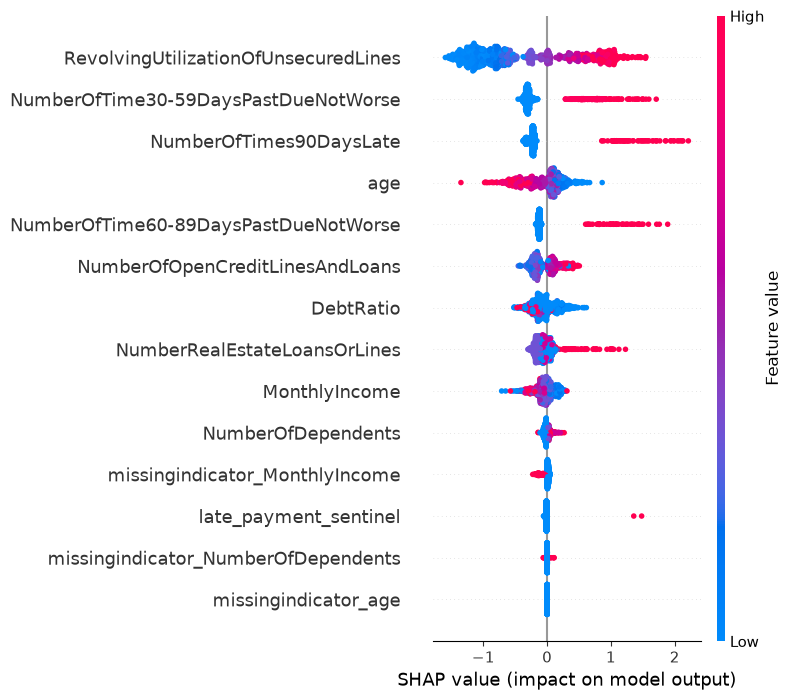

SHAP summary plot saved successfully!


In [21]:
# Generate SHAP summary plot
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    show=False
)

plt.tight_layout()

plt.savefig(
    "../figures/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP summary plot saved successfully!")

In [22]:
print("False negatives shape:", false_negatives.shape)
print("False negatives columns:", false_negatives.columns.tolist())
print(false_negatives.head())

print("\nFalse positives shape:", false_positives.shape)
print("False positives columns:", false_positives.columns.tolist())
print(false_positives.head())

False negatives shape: (1015, 4)
False negatives columns: ['actual', 'probability', 'predicted', 'error_type']
     actual  probability  predicted      error_type
29        1     0.097471          0  False Negative
50        1     0.114276          0  False Negative
86        1     0.034827          0  False Negative
115       1     0.036885          0  False Negative
139       1     0.181150          0  False Negative

False positives shape: (1465, 4)
False positives columns: ['actual', 'probability', 'predicted', 'error_type']
    actual  probability  predicted      error_type
31       0     0.540412          1  False Positive
35       0     0.293365          1  False Positive
45       0     0.307785          1  False Positive
89       0     0.609625          1  False Positive
99       0     0.261183          1  False Positive


In [23]:
# Select the first false-negative example
fn_idx = false_negatives.index[0]

print("Selected test row:", fn_idx)
print(false_negatives.loc[fn_idx])

Selected test row: 29
actual                      1
probability          0.097471
predicted                   0
error_type     False Negative
Name: 29, dtype: object


In [25]:
test = pd.read_csv("../data/test.csv")

X_test = test.drop(columns=[TARGET_COL])

print("Test features shape:", X_test.shape)
print("Test index range:", X_test.index.min(), "to", X_test.index.max())

Test features shape: (30000, 10)
Test index range: 0 to 29999


In [26]:
fn_idx = false_negatives.index[0]

X_fn = X_test.iloc[[int(fn_idx)]]

print("Selected row:", fn_idx)
print("Selected customer shape:", X_fn.shape)

Selected row: 29
Selected customer shape: (1, 10)


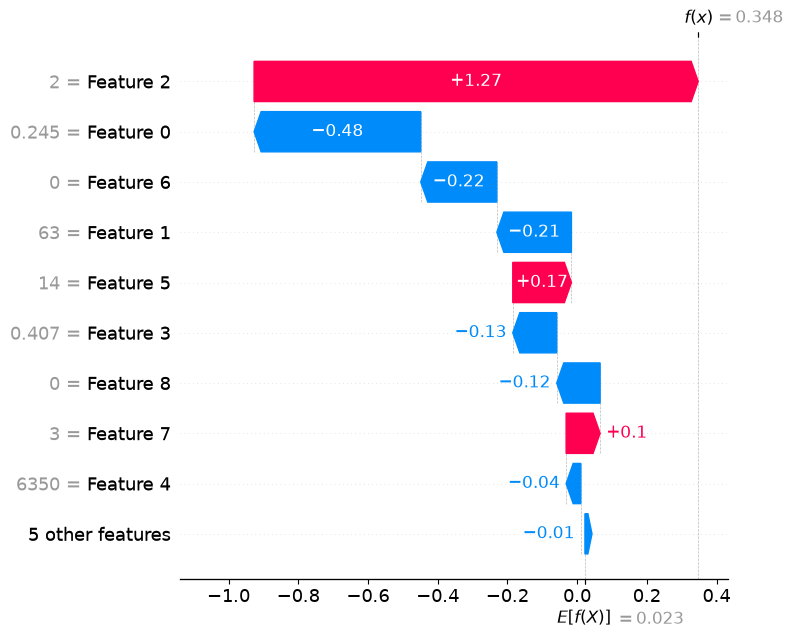

False-negative SHAP plot saved!


In [27]:
X_fn_transformed = tuned_xgb[:-1].transform(X_fn)

fn_explanation = explainer(X_fn_transformed)

shap.plots.waterfall(
    fn_explanation[0],
    show=False
)

plt.tight_layout()

plt.savefig(
    "../figures/shap_fn_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("False-negative SHAP plot saved!")

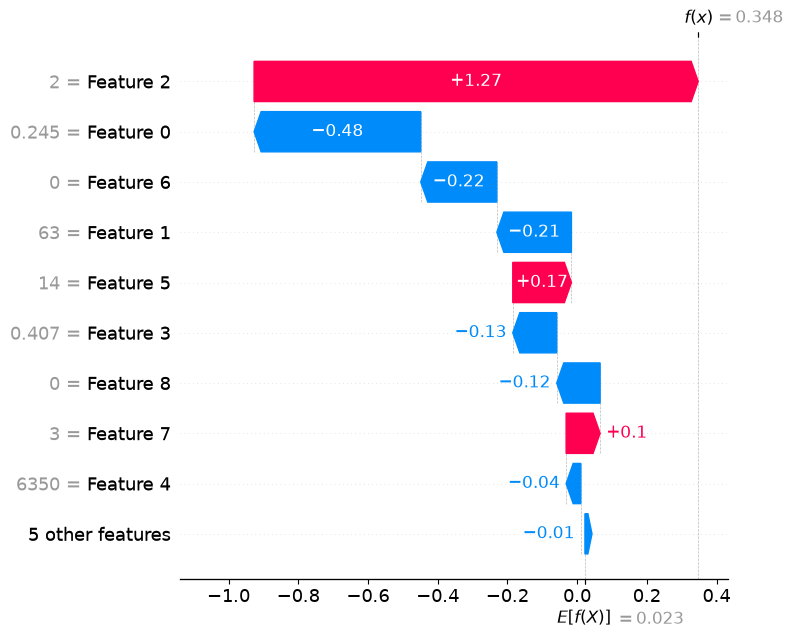

False-negative SHAP plot saved!


In [28]:
# Select the corresponding original test features
X_fn = X_test.loc[[fn_idx]]

# Apply the same preprocessing used by the trained model
X_fn_transformed = tuned_xgb[:-1].transform(X_fn)

# Generate SHAP explanation
fn_explanation = explainer(X_fn_transformed)

# Plot waterfall explanation
shap.plots.waterfall(
    fn_explanation[0],
    show=False
)

plt.tight_layout()

plt.savefig(
    "../figures/shap_fn_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("False-negative SHAP plot saved!")

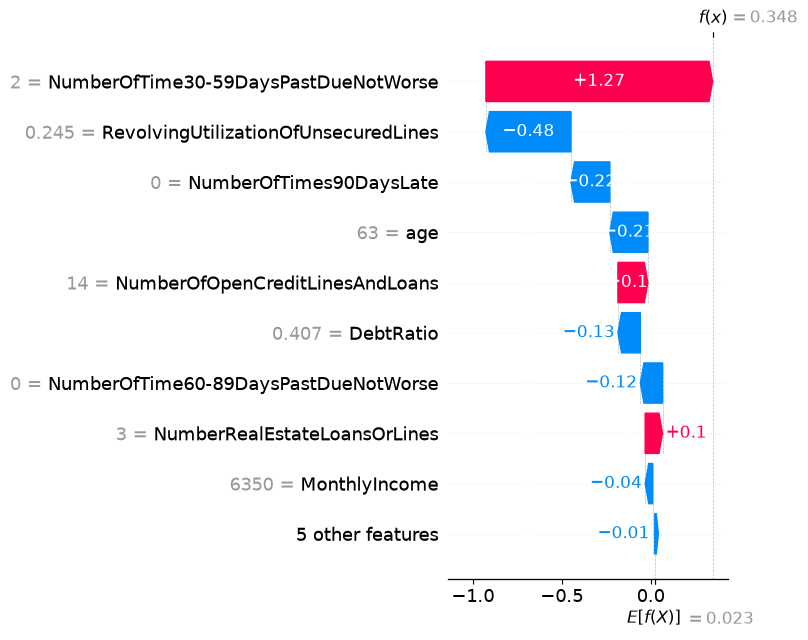

Named false-negative SHAP plot saved!


In [29]:
# Attach actual feature names to transformed data
X_fn_named = pd.DataFrame(
    X_fn_transformed,
    columns=feature_names,
    index=X_fn.index
)

# Generate named SHAP explanation
fn_explanation = explainer(X_fn_named)

# Plot
shap.plots.waterfall(fn_explanation[0], show=False)

plt.tight_layout()

plt.savefig(
    "../figures/shap_fn_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Named false-negative SHAP plot saved!")

In [30]:
fp_idx = false_positives.index[0]

X_fp = X_test.loc[[fp_idx]]

print("Selected false-positive index:", fp_idx)
print("Actual value:", errors.loc[fp_idx, "actual"])
print("Predicted probability:", errors.loc[fp_idx, "probability"])

Selected false-positive index: 31
Actual value: 0
Predicted probability: 0.5404119849205017


In [31]:
X_fp_transformed = tuned_xgb[:-1].transform(X_fp)

X_fp_named = pd.DataFrame(
    X_fp_transformed,
    columns=feature_names,
    index=X_fp.index
)

print("Transformed shape:", X_fp_named.shape)

Transformed shape: (1, 14)


In [32]:
fp_explanation = explainer(X_fp_named)


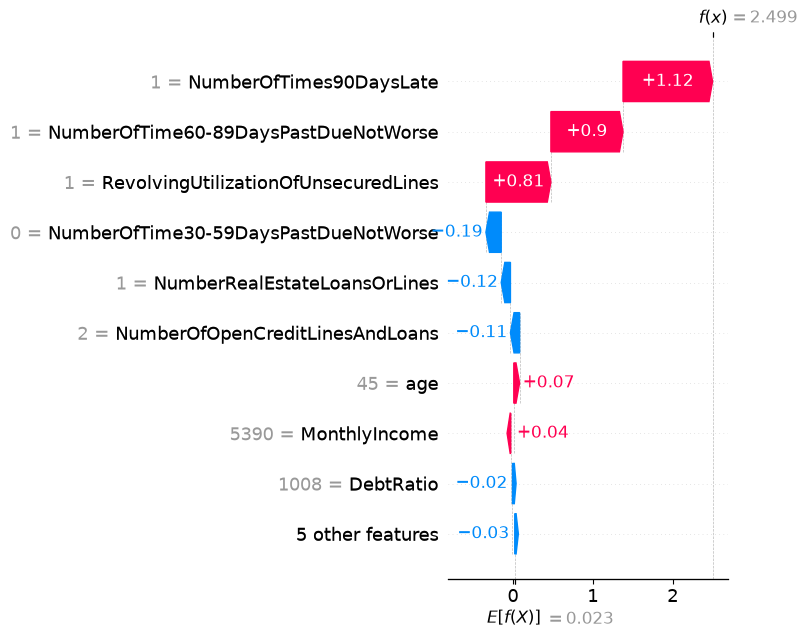

False-positive SHAP plot saved!


In [33]:
shap.plots.waterfall(fp_explanation[0], show=False)

plt.tight_layout()

plt.savefig(
    "../figures/shap_fp_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("False-positive SHAP plot saved!")

In [34]:
from pathlib import Path

files = [
    "../figures/shap_summary.png",
    "../figures/shap_fn_example.png",
    "../figures/shap_fp_example.png"
]

for file in files:
    path = Path(file)
    print(file, "->", "EXISTS" if path.exists() else "MISSING")

../figures/shap_summary.png -> EXISTS
../figures/shap_fn_example.png -> EXISTS
../figures/shap_fp_example.png -> EXISTS
